# BÀI THỰC HÀNH 4: MẠNG NEURAL HỒI QUY


<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses.

Bộ dữ liệu sử dụng: [PhoMT](https://drive.google.com/drive/folders/186OAOuSEYEDVcry7WP5UBdqECXo26QAb?usp=drive_link).


#### Bài 1: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.


In [1]:
#Import libs
import json, random, time, unicodedata
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pad_packed_sequence, pack_padded_sequence
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

#Set fixed seed for run
def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

#Set device runtime
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#Set data path and four special token ids
DATA_PATH = Path.cwd() / 'dataset'
PAD, UNK, BOS, EOS = 0, 1, 2, 3
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']

seed_all()
print(torch.__version__, device)
print('Data:', DATA_PATH)


2.14.1+cu126 cuda
Data: /home/ngt/Documents/5th-semester/DS201/lab/lab_4/dataset


In [2]:
#Config for Part C: 3 LSTM layers, hidden 256, dropout 0.3, Adam lr 1e-3
cfg = dict(
    emb=256,
    hidden=256,
    layers=3,
    dropout=0.3,
    batch=32,
    lr=1e-3,
    teacher_ratio=0.5,
    epochs=10,
    max_words=50,
    vocab_limit=10000,
    min_freq=2,
)
for k, v in cfg.items():
    print(f'{k:14}= {v}')


emb           = 256
hidden        = 256
layers        = 3
dropout       = 0.3
batch         = 32
lr            = 0.001
teacher_ratio = 0.5
epochs        = 10
max_words     = 50
vocab_limit   = 10000
min_freq      = 2


In [3]:
#Normalize text: drop BOM, NFC, lowercase, split by whitespace
def tokens(text):
    text = unicodedata.normalize('NFC', text.replace('\ufeff', ''))
    return text.lower().split()

print(tokens('Tôi YÊU bạn'))


['tôi', 'yêu', 'bạn']


In [4]:
#Load three small-PhoMT splits, keep pairs of 1..max_words tokens on both sides
raw, filtered = {}, {}
for split in ['train', 'dev', 'test']:
    path = DATA_PATH / f'small-{split}.json'
    raw[split] = json.loads(path.read_text(encoding='utf-8-sig'))
    filtered[split] = []
    for i, row in enumerate(raw[split]):
        source, target = tokens(row['english']), tokens(row['vietnamese'])
        keep = 1 <= len(source) <= cfg['max_words']
        keep = keep and 1 <= len(target) <= cfg['max_words']
        if keep:
            filtered[split].append(dict(id=i, src=source, tgt=target))
    print(f"{split:6}| raw: {len(raw[split]):6}| kept: {len(filtered[split]):6}")


train | raw:  20000| kept:  18607
dev   | raw:   2000| kept:   1901
test  | raw:   2000| kept:   1786


In [5]:
#Build a vocab from train only: 4 special tokens + tokens with freq >= min_freq
def make_vocab(sequences):
    freq = Counter(token for seq in sequences for token in seq)
    ranked = sorted(freq, key=lambda token: (-freq[token], token))
    keep = [token for token in ranked
            if freq[token] >= cfg['min_freq'] and token not in SPECIAL]
    return {token: i for i, token in
            enumerate(SPECIAL + keep[:cfg['vocab_limit'] - 4])}

#English source vocab, Vietnamese target vocab and the inverse target map
src_vocab = make_vocab(row['src'] for row in filtered['train'])
tgt_vocab = make_vocab(row['tgt'] for row in filtered['train'])
tgt_itos = {i: token for token, i in tgt_vocab.items()}

print('Source vocab:', len(src_vocab), '| Target vocab:', len(tgt_vocab))
print('Special IDs:', {token: src_vocab[token] for token in SPECIAL})


Source vocab: 8943 | Target vocab: 4003
Special IDs: {'<pad>': 0, '<unk>': 1, '<bos>': 2, '<eos>': 3}


In [6]:
#Token -> id; token missing from the vocab becomes UNK
def encode(seq, vocab):
    return [vocab.get(token, UNK) for token in seq]

#Batch: source gets EOS, target gets BOS/EOS, right padding with PAD
def collate(rows):
    src = [torch.tensor(encode(row['src'], src_vocab) + [EOS])
           for row in rows]
    tgt = [torch.tensor([BOS] + encode(row['tgt'], tgt_vocab) + [EOS])
           for row in rows]
    return dict(
        src=pad_sequence(src, batch_first=True, padding_value=PAD),
        lengths=torch.tensor([len(x) for x in src]),
        tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
        refs=[' '.join(row['tgt']) for row in rows],
        ids=[row['id'] for row in rows],
    )

#Same batch order for all three models, using every filtered row
def loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg['batch'], shuffle=shuffle,
                      collate_fn=collate,
                      generator=torch.Generator().manual_seed(42))

train_rows, dev_rows = filtered['train'], filtered['dev']
print('Train:', len(train_rows), '| dev:', len(dev_rows),
      '| batch per epoch:', len(loader(train_rows)))


Train: 18607 | dev: 1901 | batch per epoch: 582


In [7]:
#Encoder: Embedding -> packed LSTM -> memory [B, S, H] and (h, c) [K, B, H]
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(emb, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(
            self.drop(self.emb(src)), lengths.cpu(),
            batch_first=True, enforce_sorted=False)
        packed_out, state = self.rnn(packed)
        memory, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=src.size(1))
        return memory, state


In [8]:
#Two scoring styles: Bahdanau (additive) and Luong general (multiplicative)
class Attention(nn.Module):
    def __init__(self, hidden, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':
            self.Wq = nn.Linear(hidden, hidden, bias=False)
            self.Wk = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False)
        elif mode == 'luong':
            self.W = nn.Linear(hidden, hidden, bias=False)
        else:
            raise ValueError(mode)

    def forward(self, query, memory, mask):
        if self.mode == 'bahdanau':
            energy = torch.tanh(self.Wq(query).unsqueeze(1)
                                + self.Wk(memory))
            scores = self.v(energy).squeeze(-1)
        else:
            scores = torch.bmm(self.W(memory),
                               query.unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights


In [9]:
#Decoder runs one step at a time; mode = 'none', 'bahdanau' or 'luong'
class Decoder(nn.Module):
    def __init__(self, vocab_size, mode, emb, hidden, layers, dropout):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        width = emb if mode == 'none' else emb + hidden
        self.rnn = nn.LSTM(width, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        if mode != 'none':
            self.attn = Attention(hidden, mode)
            self.fuse = nn.Linear(2*hidden, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, token, state, memory, mask, feeding):
        embedded = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':
            context, weights = self.attn(state[0][-1], memory, mask)
            rnn_input = torch.cat([embedded, context], dim=-1)
        elif self.mode == 'luong':
            rnn_input = torch.cat([embedded, feeding], dim=-1)
        else:
            rnn_input = embedded
        out, state = self.rnn(rnn_input.unsqueeze(1), state)
        query = out[:, 0]
        if self.mode == 'luong':
            context, weights = self.attn(query, memory, mask)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([query, context], -1)))
            query = feeding
        logits = self.head(self.drop(query))
        return logits, state, feeding, weights


In [10]:
#Seq2Seq = Encoder + Decoder; teacher_ratio is the chance of feeding the gold token
class Seq2Seq(nn.Module):
    def __init__(self, mode, src_size, tgt_size, **kwargs):
        super().__init__()
        self.mode = mode
        self.encoder = Encoder(src_size, **kwargs)
        self.decoder = Decoder(tgt_size, mode, **kwargs)
        self.hidden = kwargs['hidden']

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)
        mask = src != PAD
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), self.hidden)
        logits = []
        for t in range(1, tgt.size(1)):
            step, state, feeding, _ = self.decoder.step(
                token, state, memory, mask, feeding)
            logits.append(step)
            coin = torch.rand(src.size(0), device=src.device)
            predicted = step.argmax(-1).detach()
            token = torch.where(coin < teacher_ratio, tgt[:, t], predicted)
        return torch.stack(logits, dim=1)

#Shared architecture for the three exercises
model_cfg = {k: cfg[k] for k in ['emb', 'hidden', 'layers', 'dropout']}
def make_seq2seq(mode, **kwargs):
    kwargs = kwargs or model_cfg
    return Seq2Seq(mode, len(src_vocab), len(tgt_vocab), **kwargs).to(device)


In [11]:
#Greedy decoding: argmax until every sentence hits EOS or max_steps is reached
@torch.no_grad()
def generate(model, src, lengths, max_steps):
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), model.hidden)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, all_weights = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(
            token, state, memory, mask, feeding)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(-1)
        token = torch.where(finished, torch.full_like(token, EOS), token)
        outputs.append(token)
        if weights is not None:
            all_weights.append(weights)
        finished = finished | (token == EOS)
        if bool(finished.all()):
            break
    ids = torch.stack(outputs, dim=1)
    weights = torch.stack(all_weights, dim=1) if all_weights else None
    return ids, weights


In [12]:
#Turn a sequence of ids into a sentence, stopping at EOS
def decode(ids):
    words = []
    for value in ids:
        i = int(value)
        if i == EOS:
            break
        if i not in {PAD, BOS}:
            words.append(tgt_itos[i])
    return ' '.join(words)


In [13]:
#ROUGE-L with a tokenizer that keeps Vietnamese diacritics, no stemming
class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False,
                                 tokenizer=UnicodeTokens())

#Mean sentence-level ROUGE-L, plus corpus BLEU (0-100) for reference
def translation_metrics(hypotheses, references):
    assert len(hypotheses) == len(references) > 0
    scores = [rouge.score(ref, hyp)['rougeL']
              for hyp, ref in zip(hypotheses, references)]
    bleu = BLEU(tokenize='none', lowercase=False)
    value = bleu.corpus_score(hypotheses, [references])
    return dict(
        rougeL_f1=float(np.mean([s.fmeasure for s in scores])),
        rougeL_precision=float(np.mean([s.precision for s in scores])),
        rougeL_recall=float(np.mean([s.recall for s in scores])),
        bleu=value.score,
        bleu_signature=str(bleu.get_signature()),
    )


In [14]:
#Loss ignores PAD positions of the target sentence
criterion = nn.CrossEntropyLoss(ignore_index=PAD)

#Evaluate: dev-NLL with gold targets, ROUGE-L/BLEU on sentences from generate
@torch.no_grad()
def evaluate(model, rows):
    model.eval()
    hypotheses, references = [], []
    nll, count = 0.0, 0
    for b in loader(rows):
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        target = tgt[:, 1:]
        logits = model(src, b['lengths'], tgt, teacher_ratio=1.0)
        nll += nn.functional.cross_entropy(
            logits.reshape(-1, len(tgt_vocab)), target.reshape(-1),
            ignore_index=PAD, reduction='sum').item()
        count += int((target != PAD).sum())
        generated, _ = generate(model, src, b['lengths'], cfg['max_words']+1)
        hypotheses.extend(decode(row) for row in generated.cpu())
        references.extend(b['refs'])
    metrics = translation_metrics(hypotheses, references)
    metrics['dev_nll'] = nll/count
    return metrics


In [15]:
#Train one epoch, return the mean loss per target token
def train_epoch(model, train_loader, optimizer):
    model.train()
    loss_total, tokens_total = 0.0, 0
    for b in train_loader:
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(src, b['lengths'], tgt, cfg['teacher_ratio'])
        gold = tgt[:, 1:]
        loss = criterion(logits.reshape(-1, len(tgt_vocab)),
                         gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        n = int((gold != PAD).sum())
        loss_total += loss.item()*n
        tokens_total += n
    return loss_total/tokens_total


In [16]:
#Training loop: train one epoch, score dev, keep the best checkpoint
def fit(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    train_loader = loader(train_rows, shuffle=True)
    best_key, best_state, best_epoch = (-1., float('-inf')), None, 0
    history = []
    for epoch in range(1, cfg['epochs']+1):
        seed_all(42+epoch)
        start = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter()-start
        measured = evaluate(model, dev_rows)
        key = (measured['rougeL_f1'], -measured['dev_nll'])
        if key > best_key:
            best_key, best_epoch = key, epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        history.append(dict(epoch=epoch, train_loss=train_loss,
                            seconds=seconds, **measured))
        print(f"{name} epoch {epoch}: loss={train_loss:.4f} "
              f"dev_ROUGE-L={measured['rougeL_f1']:.4f} "
              f"BLEU={measured['bleu']:.2f}")
    model.load_state_dict(best_state)
    model.eval()
    torch.save(best_state, f'{name}.pt')
    return history, best_epoch


In [17]:
#Plot train loss per token and dev ROUGE-L F1 side by side
def plot_history(history, title_prefix):
    epochs = [row['epoch'] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(epochs, [row['train_loss'] for row in history], marker='o')
    axes[0].set_title(title_prefix + ' - Train Loss')
    axes[0].set_ylabel('Loss per token')
    axes[1].plot(epochs, [row['rougeL_f1'] for row in history],
                 marker='o', color='tab:orange')
    axes[1].set_title(title_prefix + ' - Dev ROUGE-L F1')
    axes[1].set_ylabel('ROUGE-L F1')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


In [18]:
#Take 2 good and 1 bad translation from a fixed sample of rows
def show_sample_translations(model, rows, n_good=2, n_bad=1, limit=200):
    model.eval()
    sample = rows
    if len(rows) > limit:
        order = np.random.default_rng(42).permutation(len(rows))[:limit]
        sample = [rows[int(i)] for i in order]
    by_id = {row['id']: row for row in sample}

    scored = []
    for b in loader(sample):
        generated, _ = generate(model, b['src'].to(device), b['lengths'],
                                cfg['max_words']+1)
        for k, ids in enumerate(generated.cpu()):
            hypothesis = decode(ids)
            reference = b['refs'][k]
            scored.append(dict(
                row=by_id[b['ids'][k]],
                hypothesis=hypothesis,
                reference=reference,
                f1=rouge.score(reference, hypothesis)['rougeL'].fmeasure,
            ))

    #Prefer non-trivial source sentences when picking the good examples
    good = [item for item in sorted(scored, key=lambda item: -item['f1'])
            if len(item['row']['src']) >= 4] or scored
    bad = sorted(scored, key=lambda item: item['f1'])
    chosen = good[:n_good] + bad[:n_bad]
    tags = ['Đúng']*n_good + ['Sai']*n_bad

    for tag, item in zip(tags, chosen):
        print(f'[{tag}] ROUGE-L F1 = {item["f1"]:.4f}')
        print('Source    :', ' '.join(item['row']['src']))
        print('Reference :', item['reference'])
        print('Predicted :', item['hypothesis'])
        print()
    return [item['row'] for item in chosen]


In [19]:
#Attention heatmap: rows are generated tokens, columns are source tokens + EOS
def plot_attention_heatmaps(model, rows, max_samples=3):
    if model.mode == 'none':
        print('Model has no attention, nothing to plot.')
        return []

    #Short-to-medium sentences only, spread evenly over the shorter half
    ordered = sorted(rows, key=lambda row: len(row['src']))
    pool = ordered[:max(len(ordered)//2, max_samples)]
    picks = np.linspace(0, len(pool)-1, max_samples).astype(int)
    selected = [pool[int(i)] for i in picks]

    for row in selected:
        b = collate([row])
        ids, weights = generate(model, b['src'].to(device), b['lengths'],
                                cfg['max_words']+1)
        shown_ids = ids[0].cpu().tolist()
        stop = shown_ids.index(EOS)+1 if EOS in shown_ids else len(shown_ids)
        matrix = weights[0, :stop, :b['lengths'][0]].cpu().numpy()

        x_labels = row['src'] + ['<eos>']
        y_labels = [tgt_itos[i] for i in shown_ids[:stop]]
        fig, ax = plt.subplots(figsize=(max(4.0, 0.55*len(x_labels)+1.5),
                                        0.4*len(y_labels)+1.5))
        image = ax.imshow(matrix, cmap='Blues', aspect='auto', vmin=0, vmax=1)
        ax.set_xticks(range(len(x_labels)), x_labels, rotation=45, ha='right')
        ax.set_yticks(range(len(y_labels)), y_labels)
        ax.set_xlabel('Source token')
        ax.set_ylabel('Generated token')
        ax.set_title('Attention weights')
        fig.colorbar(image, ax=ax)
        fig.tight_layout()
        plt.show()

    return selected


In [20]:
#Shared stores for the three exercises
models, histories, best_epochs, test_scores = {}, {}, {}, {}


In [21]:
#Init Seq2Seq without attention, then train it
seed_all()
models['none'] = make_seq2seq('none')
print(f"Parameters: {sum(p.numel() for p in models['none'].parameters()):,}")

histories['none'], best_epochs['none'] = fit(models['none'], 'none')


Parameters: 7,500,963


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 1: loss=6.0258 dev_ROUGE-L=0.1296 BLEU=0.04


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 2: loss=5.7236 dev_ROUGE-L=0.1648 BLEU=0.59


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (11 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 9: loss=4.9550 dev_ROUGE-L=0.2223 BLEU=2.10


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none epoch 10: loss=4.8940 dev_ROUGE-L=0.2294 BLEU=2.32


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Best epoch             : 10
Test ROUGE-L F1        : 0.2334
Test ROUGE-L Precision : 0.262
Test ROUGE-L Recall    : 0.2134
Test BLEU              : 2.5385


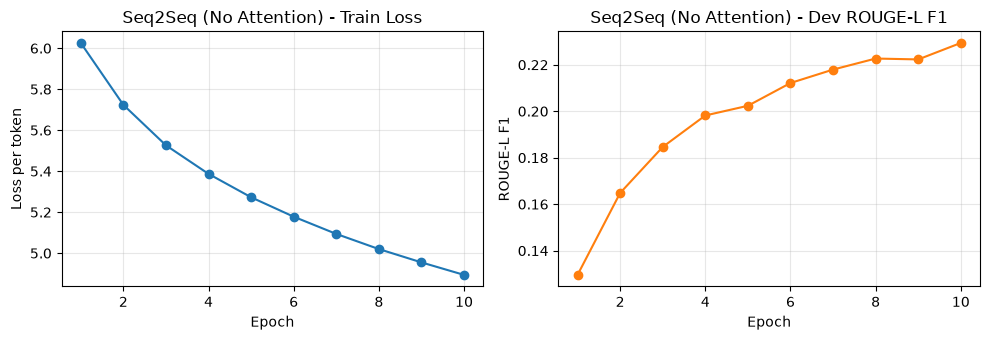

In [22]:
#Score the best checkpoint on the whole test split
test_scores['none'] = evaluate(models['none'], filtered['test'])
score = test_scores['none']
print('Best epoch             :', best_epochs['none'])
print('Test ROUGE-L F1        :', round(score['rougeL_f1'], 4))
print('Test ROUGE-L Precision :', round(score['rougeL_precision'], 4))
print('Test ROUGE-L Recall    :', round(score['rougeL_recall'], 4))
print('Test BLEU              :', round(score['bleu'], 4))

plot_history(histories['none'], 'Seq2Seq (No Attention)')


In [23]:
#Good and bad translations of the no-attention model
show_sample_translations(models['none'], filtered['test'])


[Đúng] ROUGE-L F1 = 0.5714
Source    : that 's what initially got me going on cognitive history .
Reference : đó là những gì ban đầu tôi đã đề cập về nhận thức lịch sử .
Predicted : đó là những gì tôi đã tôi về những công nghệ .

[Đúng] ROUGE-L F1 = 0.5556
Source    : we have to change the norms .
Reference : chúng ta phải thay đổi các quy tắc .
Predicted : chúng ta cần có một sự thay đổi .

[Sai] ROUGE-L F1 = 0.0278
Source    : patients " 232 " and " 233 " flew back to vietnam march 27 on aeroflot flight su290 from moscow and were quarantined in the northern province of vinh phuc .
Reference : bệnh nhân " 232 " và " 233 " đã bay trở lại việt nam vào ngày 27 tháng 3 trên chuyến bay su290 của aeroflot từ moscow và đã được cách ly ở tỉnh phía bắc vĩnh phúc .
Predicted : <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .



[{'id': 1544,
  'src': ['that',
   "'s",
   'what',
   'initially',
   'got',
   'me',
   'going',
   'on',
   'cognitive',
   'history',
   '.'],
  'tgt': ['đó',
   'là',
   'những',
   'gì',
   'ban',
   'đầu',
   'tôi',
   'đã',
   'đề',
   'cập',
   'về',
   'nhận',
   'thức',
   'lịch',
   'sử',
   '.']},
 {'id': 1381,
  'src': ['we', 'have', 'to', 'change', 'the', 'norms', '.'],
  'tgt': ['chúng', 'ta', 'phải', 'thay', 'đổi', 'các', 'quy', 'tắc', '.']},
 {'id': 218,
  'src': ['patients',
   '"',
   '232',
   '"',
   'and',
   '"',
   '233',
   '"',
   'flew',
   'back',
   'to',
   'vietnam',
   'march',
   '27',
   'on',
   'aeroflot',
   'flight',
   'su290',
   'from',
   'moscow',
   'and',
   'were',
   'quarantined',
   'in',
   'the',
   'northern',
   'province',
   'of',
   'vinh',
   'phuc',
   '.'],
  'tgt': ['bệnh',
   'nhân',
   '"',
   '232',
   '"',
   'và',
   '"',
   '233',
   '"',
   'đã',
   'bay',
   'trở',
   'lại',
   'việt',
   'nam',
   'vào',
   'ngày',
 

#### Bài 2: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.


In [24]:
#Init Seq2Seq with Bahdanau attention, then train it
seed_all()
models['bahdanau'] = make_seq2seq('bahdanau')
print(f"Parameters: {sum(p.numel() for p in models['bahdanau'].parameters()):,}")

histories['bahdanau'], best_epochs['bahdanau'] = fit(models['bahdanau'], 'bahdanau')


Parameters: 8,025,763


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 1: loss=6.0425 dev_ROUGE-L=0.1412 BLEU=0.15


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 2: loss=5.6467 dev_ROUGE-L=0.1923 BLEU=1.05


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (11 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 9: loss=4.5691 dev_ROUGE-L=0.2947 BLEU=4.59


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau epoch 10: loss=4.4876 dev_ROUGE-L=0.3006 BLEU=4.43


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Best epoch             : 10
Test ROUGE-L F1        : 0.3127
Test ROUGE-L Precision : 0.3434
Test ROUGE-L Recall    : 0.2911
Test BLEU              : 5.4512


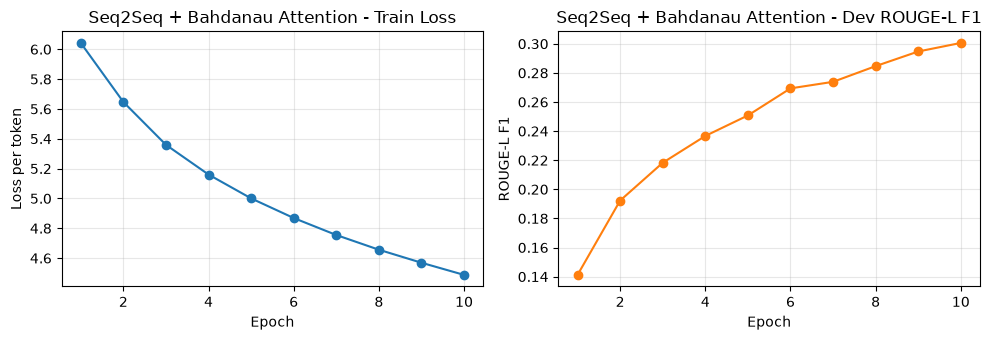

In [25]:
#Score the best checkpoint on the whole test split
test_scores['bahdanau'] = evaluate(models['bahdanau'], filtered['test'])
score = test_scores['bahdanau']
print('Best epoch             :', best_epochs['bahdanau'])
print('Test ROUGE-L F1        :', round(score['rougeL_f1'], 4))
print('Test ROUGE-L Precision :', round(score['rougeL_precision'], 4))
print('Test ROUGE-L Recall    :', round(score['rougeL_recall'], 4))
print('Test BLEU              :', round(score['bleu'], 4))

plot_history(histories['bahdanau'], 'Seq2Seq + Bahdanau Attention')


In [26]:
#Good and bad translations of the Bahdanau model
show_sample_translations(models['bahdanau'], filtered['test'])


[Đúng] ROUGE-L F1 = 0.7059
Source    : we have to change the norms .
Reference : chúng ta phải thay đổi các quy tắc .
Predicted : chúng ta phải thay đổi sự khí .

[Đúng] ROUGE-L F1 = 0.6667
Source    : but i want to start and go back to the 1930s .
Reference : nhưng tôi muốn bắt đầu từ những năm 1930 .
Predicted : nhưng tôi muốn bắt đầu và đi vào những <unk> .

[Sai] ROUGE-L F1 = 0.0656
Source    : jehovah 's witnesses worldwide are deeply disappointed that with its arbitrary decision , russia 's supreme court has effectively banned their worship throughout the country .
Reference : nhân chứng giê-hô-va trên khắp thế giới rất thất vọng trước phán quyết độc đoán ấy , toà tối cao nga đã cấm đoán sự thờ phượng của nhân chứng trên khắp nước này .
Predicted : <unk> <unk> là quyền lực đang được được ra những với những với những <unk> , , <unk> , <unk> <unk> , <unk> <unk> <unk> .



[{'id': 1381,
  'src': ['we', 'have', 'to', 'change', 'the', 'norms', '.'],
  'tgt': ['chúng', 'ta', 'phải', 'thay', 'đổi', 'các', 'quy', 'tắc', '.']},
 {'id': 326,
  'src': ['but',
   'i',
   'want',
   'to',
   'start',
   'and',
   'go',
   'back',
   'to',
   'the',
   '1930s',
   '.'],
  'tgt': ['nhưng',
   'tôi',
   'muốn',
   'bắt',
   'đầu',
   'từ',
   'những',
   'năm',
   '1930',
   '.']},
 {'id': 55,
  'src': ['jehovah',
   "'s",
   'witnesses',
   'worldwide',
   'are',
   'deeply',
   'disappointed',
   'that',
   'with',
   'its',
   'arbitrary',
   'decision',
   ',',
   'russia',
   "'s",
   'supreme',
   'court',
   'has',
   'effectively',
   'banned',
   'their',
   'worship',
   'throughout',
   'the',
   'country',
   '.'],
  'tgt': ['nhân',
   'chứng',
   'giê-hô-va',
   'trên',
   'khắp',
   'thế',
   'giới',
   'rất',
   'thất',
   'vọng',
   'trước',
   'phán',
   'quyết',
   'độc',
   'đoán',
   'ấy',
   ',',
   'toà',
   'tối',
   'cao',
   'nga',
   'đã',
 

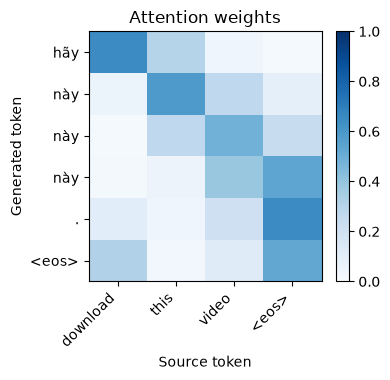

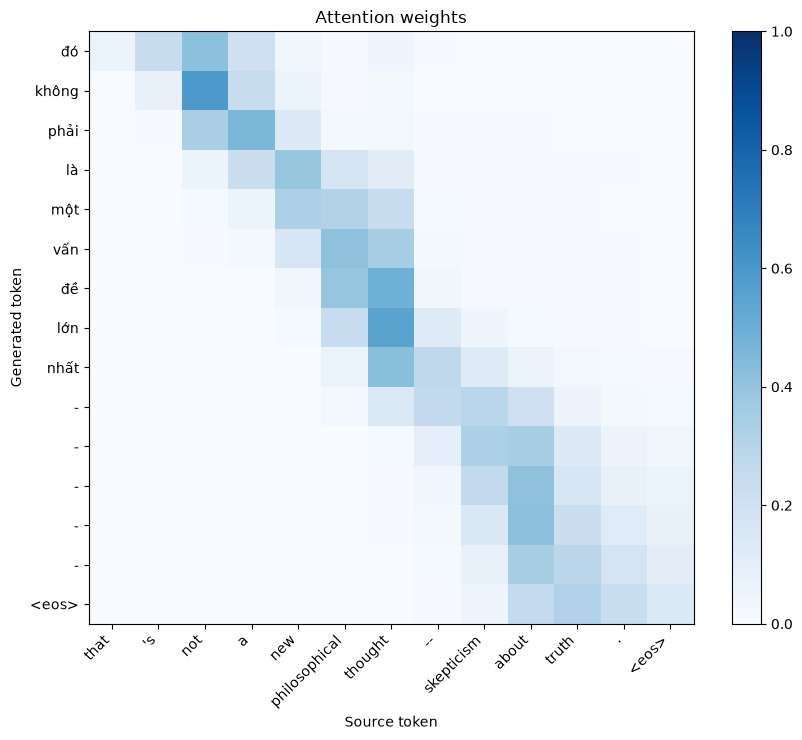

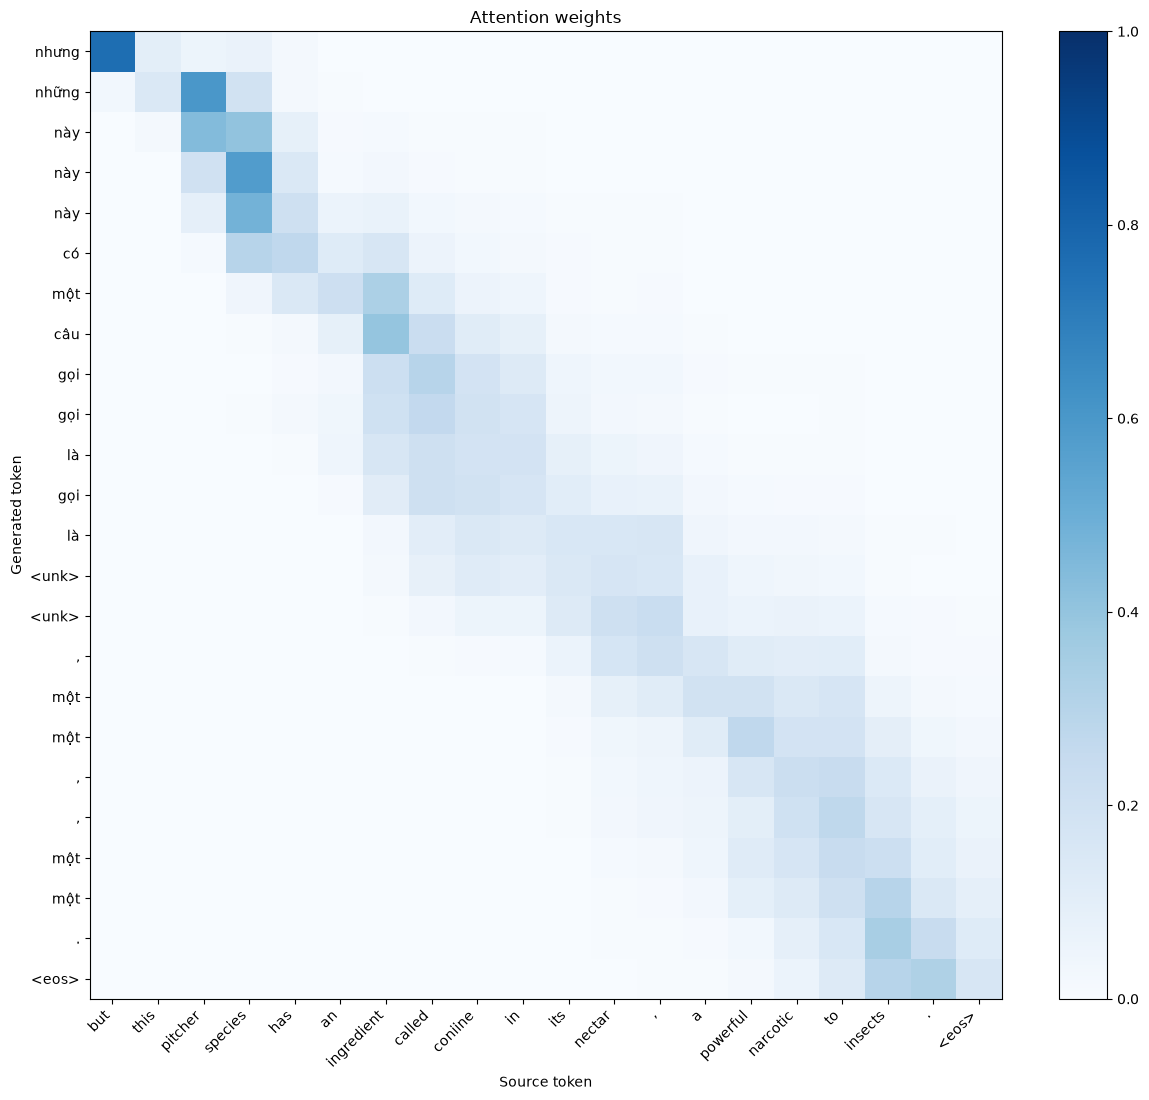

[{'id': 123,
  'src': ['download', 'this', 'video'],
  'tgt': ['tải', 'video', 'này', 'về']},
 {'id': 1612,
  'src': ['that',
   "'s",
   'not',
   'a',
   'new',
   'philosophical',
   'thought',
   '--',
   'skepticism',
   'about',
   'truth',
   '.'],
  'tgt': ['đó',
   'không',
   'phải',
   'một',
   'suy',
   'nghĩ',
   'triết',
   'học',
   'mới',
   '--',
   'lòng',
   'hoài',
   'nghi',
   'về',
   'sự',
   'thật',
   '.']},
 {'id': 293,
  'src': ['but',
   'this',
   'pitcher',
   'species',
   'has',
   'an',
   'ingredient',
   'called',
   'coniine',
   'in',
   'its',
   'nectar',
   ',',
   'a',
   'powerful',
   'narcotic',
   'to',
   'insects',
   '.'],
  'tgt': ['nhưng',
   'một',
   'thành',
   'phần',
   'trong',
   'mật',
   'hoa',
   'gọi',
   'là',
   'conine',
   ',',
   'là',
   'chất',
   'gây',
   'mê',
   'mạnh',
   'với',
   'côn',
   'trùng',
   '.']}]

In [27]:
#Attention heatmaps of 3 short-to-medium test sentences
plot_attention_heatmaps(models['bahdanau'], filtered['test'], max_samples=3)


#### Bài 3: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Effective Approaches to Attention-based Neural Machine Translation](https://arxiv.org/abs/1508.04025)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.


In [28]:
#Init Seq2Seq with Luong attention, then train it
seed_all()
models['luong'] = make_seq2seq('luong')
print(f"Parameters: {sum(p.numel() for p in models['luong'].parameters()):,}")

histories['luong'], best_epochs['luong'] = fit(models['luong'], 'luong')


Parameters: 7,959,971


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 1: loss=6.0772 dev_ROUGE-L=0.1262 BLEU=0.04


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 2: loss=5.7459 dev_ROUGE-L=0.1707 BLEU=0.85


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (11 outputs left out)

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 9: loss=4.6277 dev_ROUGE-L=0.2844 BLEU=4.22


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong epoch 10: loss=4.5374 dev_ROUGE-L=0.2920 BLEU=4.44


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Best epoch             : 10
Test ROUGE-L F1        : 0.3066
Test ROUGE-L Precision : 0.3362
Test ROUGE-L Recall    : 0.2859
Test BLEU              : 5.4852


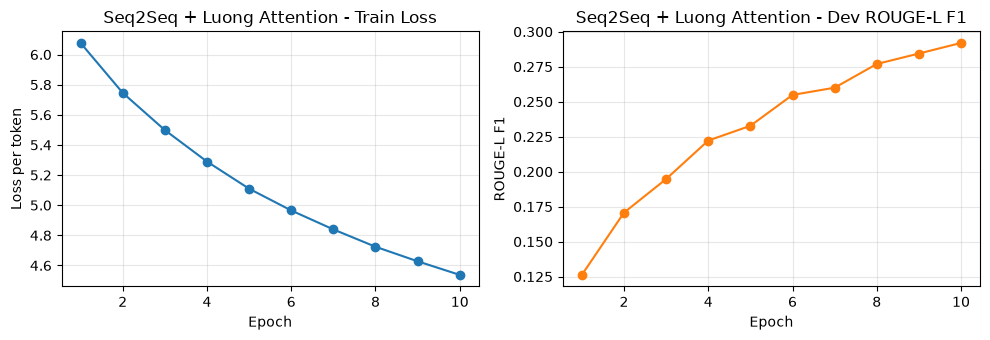

In [29]:
#Score the best checkpoint on the whole test split
test_scores['luong'] = evaluate(models['luong'], filtered['test'])
score = test_scores['luong']
print('Best epoch             :', best_epochs['luong'])
print('Test ROUGE-L F1        :', round(score['rougeL_f1'], 4))
print('Test ROUGE-L Precision :', round(score['rougeL_precision'], 4))
print('Test ROUGE-L Recall    :', round(score['rougeL_recall'], 4))
print('Test BLEU              :', round(score['bleu'], 4))

plot_history(histories['luong'], 'Seq2Seq + Luong Attention')


In [30]:
#Good and bad translations of the Luong model
show_sample_translations(models['luong'], filtered['test'])


[Đúng] ROUGE-L F1 = 0.7500
Source    : we have to change the norms .
Reference : chúng ta phải thay đổi các quy tắc .
Predicted : chúng ta phải thay đổi đổi .

[Đúng] ROUGE-L F1 = 0.6667
Source    : and the question was : what do we have to do to make sure that our company lasts 100 years ?
Reference : và câu hỏi là : chúng ta phải làm gì để đảm bảo công ty tồn tại 100 năm ?
Predicted : và câu hỏi là : chúng ta phải làm gì để làm những những công nghệ ở năm năm năm năm ?

[Sai] ROUGE-L F1 = 0.0690
Source    : the binh thuan border defense force and the phu quy search and rescue station dispatched ships to the scene to rescue the crew members .
Reference : lực lượng biên phòng tỉnh bình thuận và trạm tìm kiếm cứu nạn phú quý đã điều động tàu đến hiện trường cứu các thuyền viên .
Predicted : những <unk> <unk> <unk> <unk> <unk> <unk> và và <unk> và <unk> và <unk> và và <unk> và <unk> và <unk> và <unk> để để để để để cho những .



[{'id': 1381,
  'src': ['we', 'have', 'to', 'change', 'the', 'norms', '.'],
  'tgt': ['chúng', 'ta', 'phải', 'thay', 'đổi', 'các', 'quy', 'tắc', '.']},
 {'id': 1951,
  'src': ['and',
   'the',
   'question',
   'was',
   ':',
   'what',
   'do',
   'we',
   'have',
   'to',
   'do',
   'to',
   'make',
   'sure',
   'that',
   'our',
   'company',
   'lasts',
   '100',
   'years',
   '?'],
  'tgt': ['và',
   'câu',
   'hỏi',
   'là',
   ':',
   'chúng',
   'ta',
   'phải',
   'làm',
   'gì',
   'để',
   'đảm',
   'bảo',
   'công',
   'ty',
   'tồn',
   'tại',
   '100',
   'năm',
   '?']},
 {'id': 89,
  'src': ['the',
   'binh',
   'thuan',
   'border',
   'defense',
   'force',
   'and',
   'the',
   'phu',
   'quy',
   'search',
   'and',
   'rescue',
   'station',
   'dispatched',
   'ships',
   'to',
   'the',
   'scene',
   'to',
   'rescue',
   'the',
   'crew',
   'members',
   '.'],
  'tgt': ['lực',
   'lượng',
   'biên',
   'phòng',
   'tỉnh',
   'bình',
   'thuận',
   'và',
  

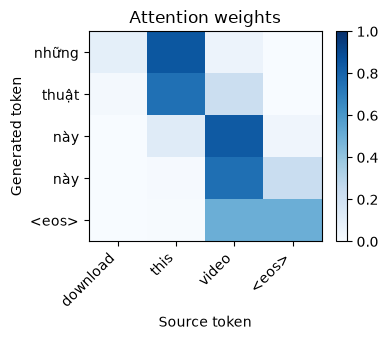

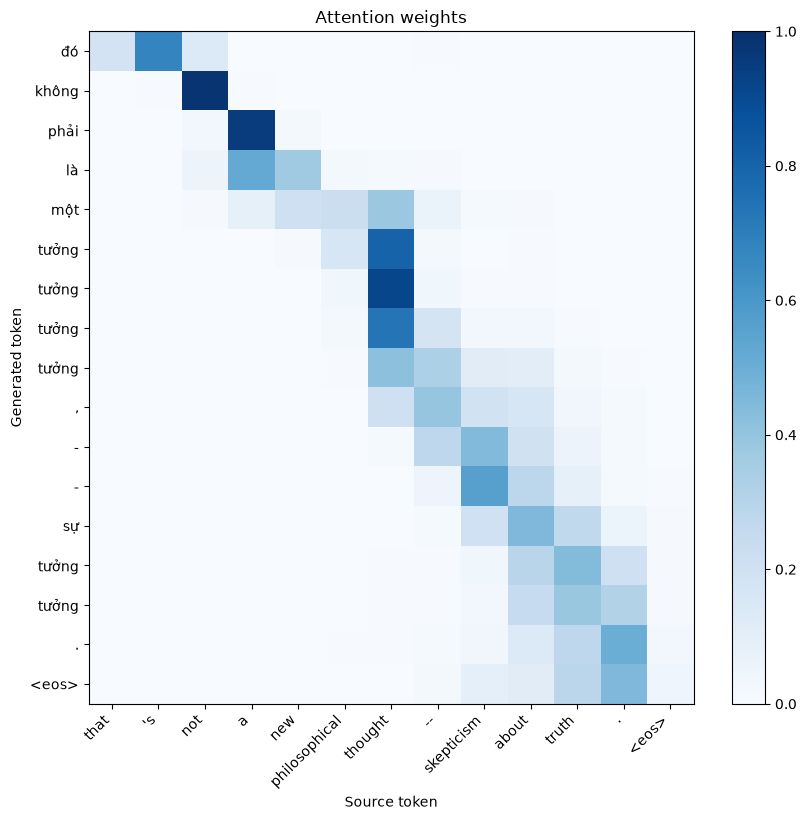

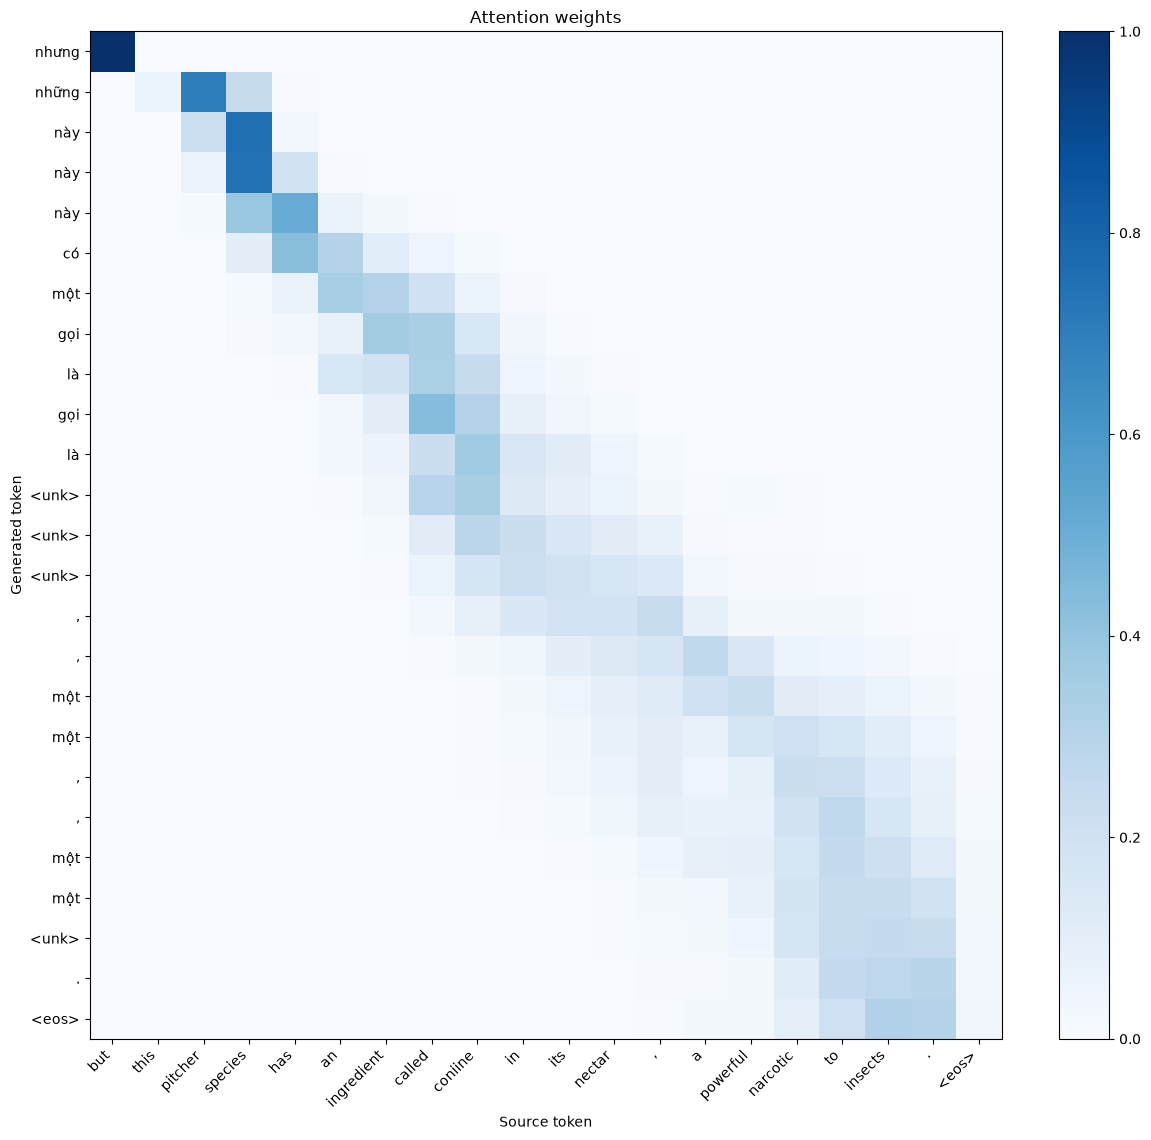

[{'id': 123,
  'src': ['download', 'this', 'video'],
  'tgt': ['tải', 'video', 'này', 'về']},
 {'id': 1612,
  'src': ['that',
   "'s",
   'not',
   'a',
   'new',
   'philosophical',
   'thought',
   '--',
   'skepticism',
   'about',
   'truth',
   '.'],
  'tgt': ['đó',
   'không',
   'phải',
   'một',
   'suy',
   'nghĩ',
   'triết',
   'học',
   'mới',
   '--',
   'lòng',
   'hoài',
   'nghi',
   'về',
   'sự',
   'thật',
   '.']},
 {'id': 293,
  'src': ['but',
   'this',
   'pitcher',
   'species',
   'has',
   'an',
   'ingredient',
   'called',
   'coniine',
   'in',
   'its',
   'nectar',
   ',',
   'a',
   'powerful',
   'narcotic',
   'to',
   'insects',
   '.'],
  'tgt': ['nhưng',
   'một',
   'thành',
   'phần',
   'trong',
   'mật',
   'hoa',
   'gọi',
   'là',
   'conine',
   ',',
   'là',
   'chất',
   'gây',
   'mê',
   'mạnh',
   'với',
   'côn',
   'trùng',
   '.']}]

In [31]:
#Attention heatmaps of 3 short-to-medium test sentences
plot_attention_heatmaps(models['luong'], filtered['test'], max_samples=3)


,Mô hình,ROUGE-L dev,ROUGE-L test,BLEU test,Best Epoch,Số tham số,Giây/epoch
0,Bài 1. Không attention,0.2294,0.2334,2.5385,10,"7,500,963",33.1093
1,Bài 2. Bahdanau,0.3006,0.3127,5.4512,10,"8,025,763",51.4757
2,Bài 3. Luong,0.2920,0.3066,5.4852,10,"7,959,971",54.4371


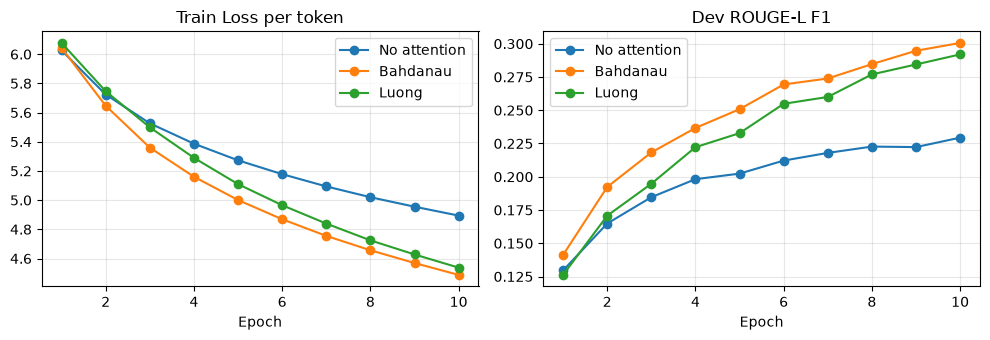

In [32]:
#Summary table of Part C.2 plus the learning curves of the three models
summary = []
for name, label in [('none', 'Bài 1. Không attention'),
                    ('bahdanau', 'Bài 2. Bahdanau'),
                    ('luong', 'Bài 3. Luong')]:
    best = next(row for row in histories[name]
                if row['epoch'] == best_epochs[name])
    summary.append({
        'Mô hình': label,
        'ROUGE-L dev': best['rougeL_f1'],
        'ROUGE-L test': test_scores[name]['rougeL_f1'],
        'BLEU test': test_scores[name]['bleu'],
        'Best Epoch': best_epochs[name],
        'Số tham số': sum(p.numel() for p in models[name].parameters()),
        'Giây/epoch': float(np.mean([row['seconds'] for row in histories[name]])),
    })

table = pd.DataFrame(summary)
score_cols = ['ROUGE-L dev', 'ROUGE-L test', 'BLEU test', 'Giây/epoch']
table[score_cols] = table[score_cols].round(4)
table['Số tham số'] = table['Số tham số'].map('{:,}'.format)
display(table)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, label in [('none', 'No attention'),
                    ('bahdanau', 'Bahdanau'),
                    ('luong', 'Luong')]:
    epochs = [row['epoch'] for row in histories[name]]
    axes[0].plot(epochs, [row['train_loss'] for row in histories[name]],
                 marker='o', label=label)
    axes[1].plot(epochs, [row['rougeL_f1'] for row in histories[name]],
                 marker='o', label=label)
axes[0].set_title('Train Loss per token')
axes[1].set_title('Dev ROUGE-L F1')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()
